# Pore Diameter Comparisons with Zeo++
In this notebook, we will take the CoRE-MOF-2019 and IZA datasets from MOFDB and compare the LCD, PLD and DFSD values tabulated there with that computed using mofography, and make parity plots. 

## Importing the necessary libraries

In [16]:
#* General imports
import os, sys
import numpy as np 
from pathlib import Path 
import pandas as pd
from tqdm import tqdm
import pickle
#* Add the path to mofography to the system path
path_to_mgr = Path('C:/Users/arung/OneDrive - The University of Manchester/my_cloned_repos/22sep2024/mofography')
sys.path.append(str(path_to_mgr))


import mofography as mgr

#* Needed for cheminformatics if any
from ase.io import read, write
from ase.build import make_supercell 
from ase.geometry import complete_cell



#* for plotting
import plotly.graph_objects as go

#* Needed for the workflow
import dask
from dask import delayed
from dask.distributed import Client, progress, LocalCluster

## Load the dataset 

I have the dataset saved up, if you don't have it, check out hte getting data from MOFDB tutuorial to create and save the dataframe.

In [4]:

# df = mgr.get_data_from_mofdb(params={'vf_min': 0.7, 'vf_max': 0.75,'lcd_min':12,'lcd_max':14, 'database':'CoREMOF 2019'})
iza_df = mgr.get_data_from_mofdb(params={ 'database':'IZA'})

Output()

C:\Users\arung\OneDrive - The University of Manchester\my_cloned_repos\22sep2024\mofography\mofography\data.py:260: RuntimeWarning: coroutine 'ClientSession.close' was never awaited
  session.close()
Unclosed client session
client_session: <aiohttp.client.ClientSession object at 0x00000242348AEED0>
Unclosed connector
connections: ['[(<aiohttp.client_proto.ResponseHandler object at 0x000002423647C830>, 12649.578), (<aiohttp.client_proto.ResponseHandler object at 0x000002423647C600>, 12652.921)]']
connector: <aiohttp.connector.TCPConnector object at 0x0000024234ABE8D0>


the dataset looks like this:

In [5]:
print(iza_df.columns)
iza_df.head(10)

Index(['id', 'mofid', 'mofkey', 'hashkey', 'name', 'void_fraction',
       'surface_area_m2g', 'surface_area_m2cm3', 'pld', 'lcd', 'pxrd',
       'pore_size_distribution', 'database', 'batch_number', 'elements', 'cif',
       'url', 'adsorbates', 'heats', 'isotherms', 'mofdb_version'],
      dtype='object')


,id,mofid,mofkey,hashkey,name,void_fraction,surface_area_m2g,surface_area_m2cm3,pld,lcd,...,pore_size_distribution,database,batch_number,elements,cif,url,adsorbates,heats,isotherms,mofdb_version
0,168868,None,None,abab969925ea9f07321dff879a1be10bb40180ea94e253...,ABW-0,0.208281,0.0000,0.0000,2.88024,3.60282,...,NA,IZA,33,[],#3 6 4 2\n#O 178 0.05\n#Si 177 0.05\ndata_ABW\...,/mofs/168868.json,"[{'id': 227, 'InChIKey': 'UFHFLCQGNIYNRP-UHFFF...",[],"[{'batch_number': 33, 'adsorbates': [{'id': 22...",dc8a0295db
1,168869,None,None,be932cc86b21eb643beee0f0fb475201d744c8367f7959...,ACO-0,0.307300,18.4268,30.2701,2.93515,3.92937,...,NA,IZA,33,[],#3 3 3 2\n#O 178 0.05\n#Si 177 0.05\ndata_ACO\...,/mofs/168869.json,"[{'id': 227, 'InChIKey': 'UFHFLCQGNIYNRP-UHFFF...",[],"[{'batch_number': 33, 'adsorbates': [{'id': 22...",dc8a0295db
2,168870,None,None,91c3948bfedd5a5025456d9dd389ff2bb24e9404b3bd51...,AEI-0,0.405097,613.2570,920.8470,3.21360,6.69320,...,NA,IZA,33,[],#2 3 2 2\n#O 178 0.05\n#Si 177 0.05\ndata_AEI\...,/mofs/168870.json,"[{'id': 227, 'InChIKey': 'UFHFLCQGNIYNRP-UHFFF...",[],"[{'batch_number': 33, 'adsorbates': [{'id': 22...",dc8a0295db
3,168871,None,None,16fed0897ecea15f827ab98f107f1d36f1753c270d519e...,AEL-0,0.188830,258.3630,494.5760,3.98810,4.99656,...,NA,IZA,33,[],#4 2 3 2\n#O 178 0.05\n#Si 177 0.05\ndata_AEL\...,/mofs/168871.json,"[{'id': 227, 'InChIKey': 'UFHFLCQGNIYNRP-UHFFF...",[],"[{'batch_number': 33, 'adsorbates': [{'id': 22...",dc8a0295db
4,168872,None,None,1d39e4a00fba111b49bc6df6a69be6e43cc61c305be273...,AEN-0,0.163004,0.0000,0.0000,3.03180,3.79191,...,NA,IZA,33,[],#2 3 3 2\n#O 178 0.05\n#Si 177 0.05\ndata_AEN\...,/mofs/168872.json,"[{'id': 227, 'InChIKey': 'UFHFLCQGNIYNRP-UHFFF...",[],"[{'batch_number': 33, 'adsorbates': [{'id': 22...",dc8a0295db
5,168873,None,None,d94b6b3e15b2b2b9b42258d2f2eb8d9131c9079b138e81...,AET-0,0.243164,365.9500,664.9860,6.93817,7.76243,...,NA,IZA,33,[],#1 2 4 2\n#O 178 0.05\n#Si 177 0.05\ndata_AET\...,/mofs/168873.json,"[{'id': 227, 'InChIKey': 'UFHFLCQGNIYNRP-UHFFF...",[],"[{'batch_number': 33, 'adsorbates': [{'id': 22...",dc8a0295db
6,168874,None,None,8b451159005e20238ad3e1fc4b27487bc688521e2b39b9...,AFG-0,0.290993,247.3670,501.3640,1.91197,5.72312,...,NA,IZA,33,[],#3 3 2 2\n#O 178 0.05\n#Si 177 0.05\ndata_AFG\...,/mofs/168874.json,"[{'id': 227, 'InChIKey': 'UFHFLCQGNIYNRP-UHFFF...",[],"[{'batch_number': 33, 'adsorbates': [{'id': 22...",dc8a0295db
7,168875,None,None,ea75351a338a078026572310bb290c163040add607f622...,AFI-0,0.284171,440.3030,742.1600,6.76675,7.64110,...,NA,IZA,33,[],#3 3 4 2\n#O 178 0.05\n#Si 177 0.05\ndata_AFI\...,/mofs/168875.json,"[{'id': 227, 'InChIKey': 'UFHFLCQGNIYNRP-UHFFF...",[],"[{'batch_number': 33, 'adsorbates': [{'id': 22...",dc8a0295db
8,168876,None,None,bab2c1f23873c666e7e0ae7bb675ac0b1b1e0db40376ec...,AFN-0,0.242810,185.7230,322.3390,2.85467,4.60922,...,NA,IZA,33,[],#3 3 3 2\n#O 178 0.05\n#Si 177 0.05\ndata_AFN\...,/mofs/168876.json,"[{'id': 227, 'InChIKey': 'UFHFLCQGNIYNRP-UHFFF...",[],"[{'batch_number': 33, 'adsorbates': [{'id': 22...",dc8a0295db
9,168877,None,None,42d2ddec11301e9138750d720e54d4677423acb3272edd...,AFO-0,0.194744,237.4150,454.9690,4.41149,4.79623,...,NA,IZA,33,[],#3 2 4 2\n#O 178 0.05\n#Si 177 0.05\ndata_AFO\...,/mofs/168877.json,"[{'id': 227, 'InChIKey': 'UFHFLCQGNIYNRP-UHFFF...",[],"[{'batch_number': 33, 'adsorbates': [{'id': 22...",dc8a0295db


## Create ASE atoms objects from the dataframe

In [6]:
iza_atoms = mgr.atoms_from_mofdb_df(iza_df)

  0%|          | 0/216 [00:00<?, ?it/s]c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\ase\io\cif.py:408: UserWarning: crystal system 'orthorhombic' is not interpreted for space group Spacegroup(74, setting=1). This may result in wrong setting!
  warnings.warn(
c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\ase\io\cif.py:408: UserWarning: crystal system 'cubic' is not interpreted for space group Spacegroup(229, setting=1). This may result in wrong setting!
  warnings.warn(
c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\ase\io\cif.py:408: UserWarning: crystal system 'orthorhombic' is not interpreted for space group Spacegroup(63, setting=1). This may result in wrong setting!
  warnings.warn(
  1%|▏         | 3/216 [00:00<00:10, 20.32it/s]c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\ase\io\cif.py:408: UserWarning: crystal system 'orthorhombic' is not interpreted for space group Spacegroup(64, setting=1). This may result in wrong setting!
  warnings.warn(


## Pore diameter calculation
Let's create a nice workflow to compute pore diameters using mofography amd dask, and compute the pore diameters for IZA, in parallel.

In [7]:
def get_pore_dia_only(mat_atoms):
	lcd, pld, dfsd, _ = mgr.get_pore_dia_mgr(mat_atoms)
	return lcd, pld, dfsd

pore_dias_delayed = []
for mat_atoms in iza_atoms:
	pore_dias_delayed.append(delayed(get_pore_dia_only)(mat_atoms))


### Start a dask cluster
Start a local dask cluster for convenience.

In [8]:
client = Client()
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 4
Total threads: 16,Total memory: 15.28 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:61628,Workers: 4
Dashboard: http://127.0.0.1:8787/status,Total threads: 16
Started: Just now,Total memory: 15.28 GiB
Comm: tcp://127.0.0.1:61650,Total threads: 4
Dashboard: http://127.0.0.1:61655/status,Memory: 3.82 GiB
Nanny: tcp://127.0.0.1:61631,


### Submit jobs
These jobs are easy, so should run super fast

In [9]:
futures = dask.persist(*pore_dias_delayed)

### Collect results
Grab the results from the local cluster

In [10]:
results = client.compute(futures)
iza_pore_dias = [r.result() if r.status=='finished' else None for r in results]

In [11]:
iza_pore_dias

[(3.3441632270812987, 2.9029926872253418, 3.3441632270812987),
 (3.5209391593933104, 2.632668304443359, 3.5209391593933104),
 (6.829863510131836, 3.0819935417175293, 6.829863510131836),
 (4.841248950958252, 3.809606990814209, 4.841248950958252),
 (3.8679489707946777, 2.641408405303955, 3.8679489707946777),
 (7.832767448425293, 7.106396636962891, 7.74499698638916),
 (5.625678024291992, 1.6272905349731444, 5.625678024291992),
 (7.895248374938965, 7.021770439147949, 7.895248374938965),
 (4.638508605957031, 2.4662893295288084, 4.638507652282715),
 (4.9427141761779785, 4.240853118896484, 4.702879867553711),
 (7.684369049072266, 6.302647552490234, 7.684369049072266),
 (9.111690483093263, 5.614353141784668, 9.111690483093263),
 (7.319689712524414, 2.847338161468506, 7.319689712524414),
 (6.542441329956055, 2.502778968811035, 6.542441329956055),
 (7.358237228393555, 2.9554519271850586, 7.358237228393555),
 (7.421565017700195, 5.517448387145996, 7.421565017700195),
 (3.1102688789367674, 2.01667

## Plot IZA parity
Plot the pore diameters from MOFography and MOFDB (zeo++) for the IZA database on the same scale

In [30]:
# grab the lcd and pld values from both
lcd_mgr = np.array([d[0] if d is not None else None for d in iza_pore_dias])
lcd_zeo = iza_df['lcd'].values
pld_mgr = np.array([d[1] if d is not None else None for d in iza_pore_dias])
pld_zeo = iza_df['pld'].values


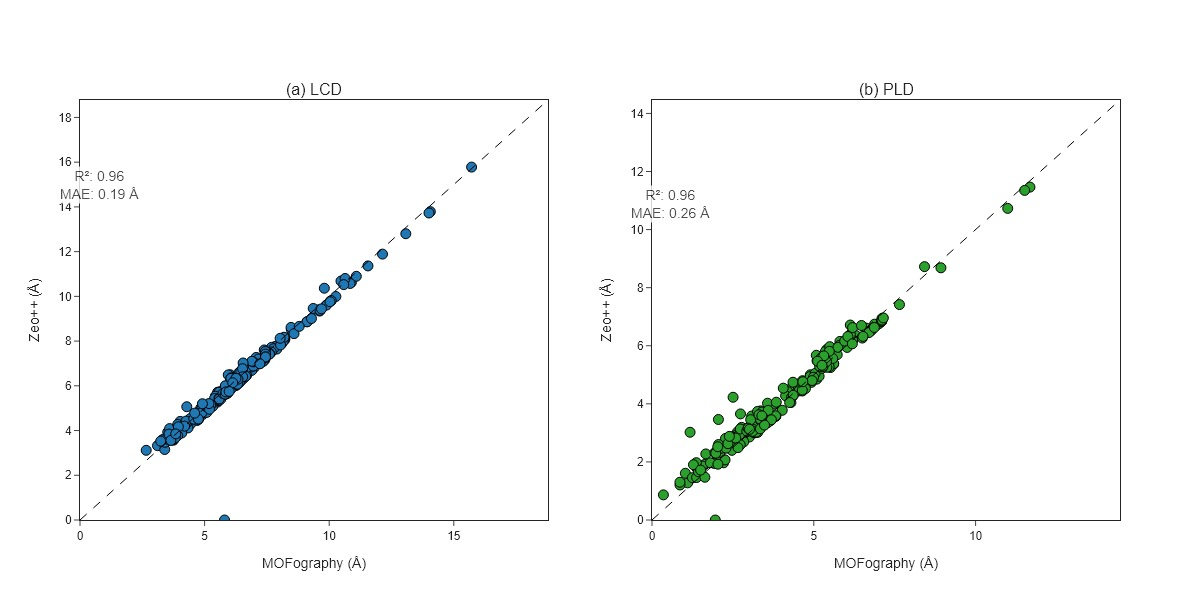

In [31]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Create subplots
fig = make_subplots(rows=1, cols=2, subplot_titles=("(a) LCD", "(b) PLD"),
                    horizontal_spacing=0.1)

# LCD subplot
fig.add_trace(
    go.Scatter(
        x=lcd_mgr,
        y=lcd_zeo,
        mode='markers',
        marker=dict(size=10, line=dict(color='black', width=1)),
        name='LCD Data'
    ),
    row=1, col=1
)
fig.add_trace(
    go.Scatter(
        x=[0, max(lcd_zeo)+3],
        y=[0, max(lcd_zeo)+3],
        mode='lines',
        line=dict(color='black', width=1, dash='dash'),
        name='LCD Parity Line'
    ),
    row=1, col=1
)

# PLD subplot
fig.add_trace(
    go.Scatter(
        x=pld_mgr,  # Assuming you have pld_mgr data
        y=pld_zeo,  # Assuming you have pld_zeo data
        mode='markers',
        marker=dict(size=10, line=dict(color='black', width=1)),
        name='PLD Data'
    ),
    row=1, col=2
)
fig.add_trace(
    go.Scatter(
        x=[0, max(pld_zeo)+3],
        y=[0, max(pld_zeo)+3],
        mode='lines',
        line=dict(color='black', width=1, dash='dash'),
        name='PLD Parity Line'
    ),
    row=1, col=2
)

# Update layout for both subplots
fig.update_layout(
    template='simple_white',
    showlegend=False,
    font=dict(family='Arial'),
    width=1200,
    height=600,
    autosize=False,
)

# Update x and y axes for both subplots
for i in [1, 2]:
    fig.update_xaxes(
        title='MOFography (\u212b)' if i == 1 else 'MOFography (\u212b)',
        titlefont=dict(size=14),
        tickfont=dict(size=12),
        mirror=True,
        showgrid=False,
        range=[0, max(lcd_zeo if i == 1 else pld_zeo) + 3],
        row=1, col=i
    )
    fig.update_yaxes(
        title='Zeo++ (\u212b)' if i == 1 else 'Zeo++ (\u212b)',
        titlefont=dict(size=14),
        tickfont=dict(size=12),
        mirror=True,
        showgrid=False,
        range=[0, max(lcd_zeo if i == 1 else pld_zeo) + 3],
        row=1, col=i
    )
from sklearn.metrics import r2_score, mean_absolute_error

# Function to remove NaN entries from both arrays
def remove_nan_pairs(arr1, arr2):
    arr1 = np.array(arr1, dtype=float)
    arr2 = np.array(arr2, dtype=float)
    mask = ~np.isnan(arr1) & ~np.isnan(arr2)
    return arr1[mask], arr2[mask]

# Remove NaN entries and compute R² and MAE for LCD
lcd_zeo_clean, lcd_mgr_clean = remove_nan_pairs(lcd_zeo, lcd_mgr)
lcd_r2 = r2_score(lcd_zeo_clean, lcd_mgr_clean)
lcd_mae = mean_absolute_error(lcd_zeo_clean, lcd_mgr_clean)

# Remove NaN entries and compute R² and MAE for PLD
pld_zeo_clean, pld_mgr_clean = remove_nan_pairs(pld_zeo, pld_mgr)
pld_r2 = r2_score(pld_zeo_clean, pld_mgr_clean)
pld_mae = mean_absolute_error(pld_zeo_clean, pld_mgr_clean)

# Add annotations for LCD
fig.add_annotation(
    text=f"R²: {lcd_r2:.2f}<br>MAE: {lcd_mae:.2f} Å",
    xref="x1", yref="y1",
    x=0.05 * max(lcd_zeo), y=0.95 * max(lcd_zeo),
    showarrow=False,
    font=dict(size=14),
    bgcolor="white",
    opacity=0.8,
    row=1, col=1
)

# Add annotations for PLD
fig.add_annotation(
    text=f"R²: {pld_r2:.2f}<br>MAE: {pld_mae:.2f} Å",
    xref="x2", yref="y2",
    x=0.05 * max(pld_zeo), y=0.95 * max(pld_zeo),
    showarrow=False,
    font=dict(size=14),
    bgcolor="white",
    opacity=0.8,
    row=1, col=2
)

fig.show(renderer='jpg')

## CoRE-MOF 2019 database
Let's test the parity plot of the same pore diameters for a subset of the coremof database

In [14]:
path_to_core_df = Path('C:/Users/arung/OneDrive - The University of Manchester/my_cloned_repos/mofography/examples/core_df_gt_05.feather')
core_df = pd.read_feather(path_to_core_df)

In [18]:
core_atoms= mgr.atoms_from_mofdb_df(core_df)
# core_atoms = pickle.load(open('../core_atoms_gt_05.pkl', 'rb'))

In [50]:
core_dias_delayed = []
for mat_atoms in core_atoms:
	core_dias_delayed.append(delayed(get_pore_dia_only)(mat_atoms))


### Submit jobs

In [52]:
futures= dask.persist(*core_dias_delayed)

c:\Users\arung\miniforge3\envs\magic\Lib\site-packages\distributed\client.py:3362: UserWarning:

Sending large graph of size 153.44 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.



### Grab the results

In [53]:
results = client.compute(futures)
core_dias = [r.result() if r.status=='finished' else None for r in results]

In [19]:
# core_dias = pickle.load(open('../coredias_gt_05.pkl', 'rb'))

### Plot the COREMOF-2019 Diameters Parity agaist MOFography

In [20]:
# grab the lcd and pld values from both
lcd_mgr = np.array([d[0] if d is not None else None for d in core_dias])
lcd_zeo = core_df['lcd'].values
pld_mgr = np.array([d[1] if d is not None else None for d in core_dias])
pld_zeo = core_df['pld'].values


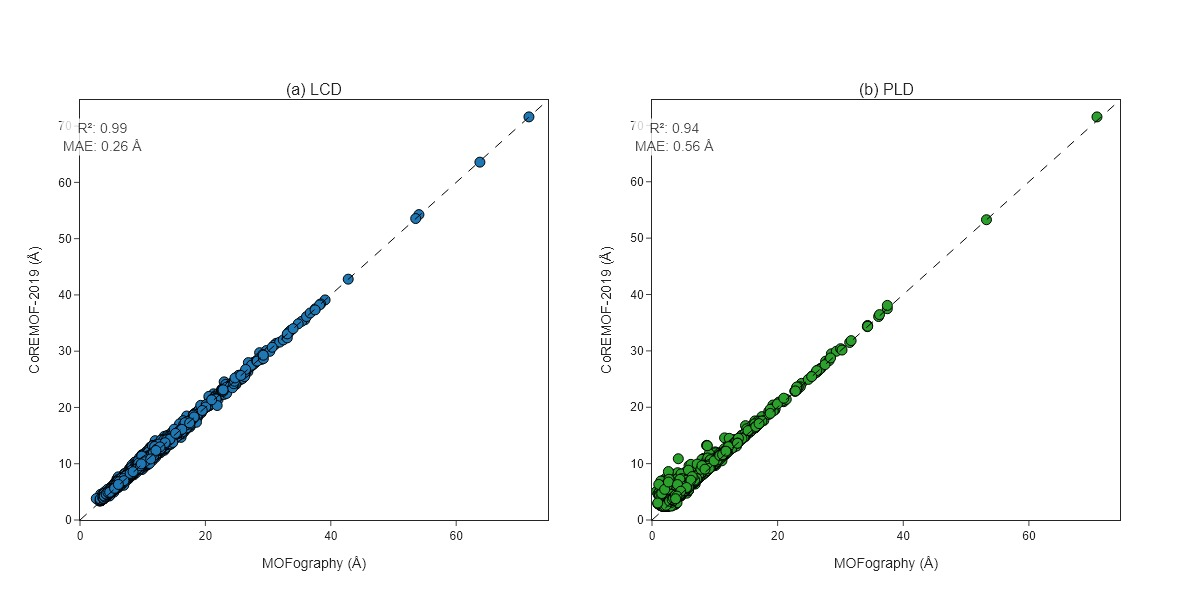

In [28]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Create subplots
fig = make_subplots(rows=1, cols=2, subplot_titles=("(a) LCD", "(b) PLD"),
                    horizontal_spacing=0.1)

# LCD subplot
fig.add_trace(
    go.Scatter(
        x=lcd_mgr,
        y=lcd_zeo,
        mode='markers',
        marker=dict(size=10, line=dict(color='black', width=1)),
        name='LCD Data'
    ),
    row=1, col=1
)
fig.add_trace(
    go.Scatter(
        x=[0, max(lcd_zeo)+3],
        y=[0, max(lcd_zeo)+3],
        mode='lines',
        line=dict(color='black', width=1, dash='dash'),
        name='LCD Parity Line'
    ),
    row=1, col=1
)

# PLD subplot
fig.add_trace(
    go.Scatter(
        x=pld_mgr,  # Assuming you have pld_mgr data
        y=pld_zeo,  # Assuming you have pld_zeo data
        mode='markers',
        marker=dict(size=10, line=dict(color='black', width=1)),
        name='PLD Data'
    ),
    row=1, col=2
)
fig.add_trace(
    go.Scatter(
        x=[0, max(pld_zeo)+3],
        y=[0, max(pld_zeo)+3],
        mode='lines',
        line=dict(color='black', width=1, dash='dash'),
        name='PLD Parity Line'
    ),
    row=1, col=2
)

# Update layout for both subplots
fig.update_layout(
    template='simple_white',
    showlegend=False,
    font=dict(family='Arial'),
    width=1200,
    height=600,
    autosize=False,

)

# Update x and y axes for both subplots
for i in [1, 2]:
    fig.update_xaxes(
        title='MOFography (\u212b)' if i == 1 else 'MOFography (\u212b)',
        titlefont=dict(size=14),
        tickfont=dict(size=12),
        mirror=True,
        showgrid=False,
        range=[0, max(lcd_zeo if i == 1 else pld_zeo) + 3],
        row=1, col=i
    )
    fig.update_yaxes(
        title='CoREMOF-2019 (\u212b)' if i == 1 else 'CoREMOF-2019 (\u212b)',
        titlefont=dict(size=14),
        tickfont=dict(size=12),
        mirror=True,
        showgrid=False,
        range=[0, max(lcd_zeo if i == 1 else pld_zeo) + 3],
        row=1, col=i
    )
from sklearn.metrics import r2_score, mean_absolute_error

# Function to remove NaN entries from both arrays
def remove_nan_pairs(arr1, arr2):
    arr1 = np.array(arr1, dtype=float)
    arr2 = np.array(arr2, dtype=float)
    mask = ~np.isnan(arr1) & ~np.isnan(arr2)
    return arr1[mask], arr2[mask]

# Remove NaN entries and compute R² and MAE for LCD
lcd_zeo_clean, lcd_mgr_clean = remove_nan_pairs(lcd_zeo, lcd_mgr)
lcd_r2 = r2_score(lcd_zeo_clean, lcd_mgr_clean)
lcd_mae = mean_absolute_error(lcd_zeo_clean, lcd_mgr_clean)

# Remove NaN entries and compute R² and MAE for PLD
pld_zeo_clean, pld_mgr_clean = remove_nan_pairs(pld_zeo, pld_mgr)
pld_r2 = r2_score(pld_zeo_clean, pld_mgr_clean)
pld_mae = mean_absolute_error(pld_zeo_clean, pld_mgr_clean)

# Add annotations for LCD
fig.add_annotation(
    text=f"R²: {lcd_r2:.2f}<br>MAE: {lcd_mae:.2f} Å",
    xref="x1", yref="y1",
    x=0.05 * max(lcd_zeo), y=0.95 * max(lcd_zeo),
    showarrow=False,
    font=dict(size=14),
    bgcolor="white",
    opacity=0.8,
    row=1, col=1
)

# Add annotations for PLD
fig.add_annotation(
    text=f"R²: {pld_r2:.2f}<br>MAE: {pld_mae:.2f} Å",
    xref="x2", yref="y2",
    x=0.05 * max(pld_zeo), y=0.95 * max(pld_zeo),
    showarrow=False,
    font=dict(size=14),
    bgcolor="white",
    opacity=0.8,
    row=1, col=2
)
# # Compute R² and MAE for LCD
# lcd_r2 = np.corrcoef(lcd_mgr, lcd_zeo)[0, 1] ** 2
# lcd_mae = np.mean(np.abs(lcd_mgr - lcd_zeo))

# # Compute R² and MAE for PLD
# pld_r2 = np.corrcoef(pld_mgr, pld_zeo)[0, 1] ** 2
# pld_mae = np.mean(np.abs(pld_mgr - pld_zeo))

# # Add annotations for LCD
# fig.add_annotation(
#     text=f"R²: {lcd_r2:.2f}<br>MAE: {lcd_mae:.2f} Å",
#     xref="paper", yref="paper",
#     x=0.1, y=0.9,  # Adjust position as needed
#     showarrow=False,
#     font=dict(size=12)
# )

# # Add annotations for PLD
# fig.add_annotation(
#     text=f"R²: {pld_r2:.2f}<br>MAE: {pld_mae:.2f} Å",
#     xref="paper", yref="paper",
#     x=0.6, y=0.9,  # Adjust position as needed
#     showarrow=False,
#     font=dict(size=12)
# )

fig.show(renderer='jpg')

### Save variables as pickled files for future use.

In [60]:
import pickle
pickle.dump(core_dias, open('coredias_gt_05.pkl', 'wb'))
pickle.dump(core_atoms, open('core_atoms_gt_05.pkl', 'wb'))
pickle.dump(iza_pore_dias, open('iza_pore_dias.pkl', 'wb'))

## Conclusions
- Computed the LCD and PLD for IZA materials and compared it with Zeo++ values tabulated in MOFDB. That is 216 all silica zeolites with no cations
- Computed the LCD and PLD for COREMOF-2019 materials  with void fraction greater than 0.5 and compared it with Zeo++ values tabulated in MOFDB. That is 7506 MOFs. 
- Made parity plots for the same and compared the accuracy of the two methods.
- The mofography calculations are much faster and use a grid spacing of 0.5 angstroms, although finer grid sizes maybe used for higher accuracy. 

